# FinTech, AI, and the Middle-Income Trap
## Joint Digital Transformation as an Escape Mechanism — Experiment Notebook

This notebook runs the full empirical experiment: data loading, index construction,
the 15 specifications, and the headline figures.

**How to use it.** By default the notebook runs on a *synthetic* panel whose
data-generating process embeds the theoretical relationships (joint-digital
complementarity, labor displacement, institutional and absorptive-capacity
channels). This lets every cell execute end-to-end before any real data is
downloaded, so you can verify the analysis code is correct. Once you have built
`data/processed/panel.parquet` from the real pipeline (`python -m src.run_pipeline`),
flip `USE_SYNTHETIC = False` and rerun.

**Theory map.** The specifications test:
- **Prediction 1 (joint digital):** the coefficient on $F \times G$ is positive.
- **Prediction 2 (absorptive capacity):** AI's effect rises with human capital and KIS share.
- **Prediction 3 (vulnerability):** AI can *deepen* the trap in low-H, low-KIS, high-exposure economies.

Results on synthetic data recover the embedded signs by construction and are
**not** evidence for the hypotheses; they only confirm the code does what the
equations say.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
sns.set_theme(style="whitegrid", context="notebook")
RNG_SEED = 42

print("Project root:", PROJECT_ROOT)

Project root: /home/claude/joint_digital_mit


In [2]:
# Toggle between synthetic and real data
USE_SYNTHETIC = True

from src.utils.synthetic_data import generate_synthetic_panel
from config.settings import DATA_PROCESSED

if USE_SYNTHETIC:
    panel = generate_synthetic_panel(n_countries=90, year_min=2017, year_max=2024, seed=RNG_SEED)
    print("Using SYNTHETIC panel (verification mode).")
else:
    panel = pd.read_parquet(DATA_PROCESSED / "panel.parquet")
    print("Using REAL panel from data/processed/panel.parquet")

print("Shape:", panel.shape)
panel.head()

Using SYNTHETIC panel (verification mode).
Shape: (720, 33)


,iso3,year,gdp_pc_growth,gdp_pc_ppp,F,G,institutions,human_capital_pwt,sigma_kis,rho_gradient4,...,F_x_I,G_x_I,G_x_H,G_x_KIS,F_x_G_x_I,displacement_term,mi_lag,at_risk,exit,slowdown_eps
0,C000,2017,2.7480,4296.9489,0.4057,0.5381,0.5225,2.1356,0.2505,0.2183,...,0.2119,0.2811,0.2456,0.1348,0.1140,0.0479,NaN,0,NaN,0.0000
1,C000,2018,1.5716,4427.8105,-0.0779,0.2389,0.4697,2.1356,0.2505,0.2183,...,-0.0366,0.1122,0.1090,0.0598,-0.0087,0.0212,1.0000,1,0.0000,0.0000
2,C000,2019,1.2522,4562.6574,0.4459,0.5356,0.6219,2.1356,0.2505,0.2183,...,0.2773,0.3331,0.2445,0.1342,0.1485,0.0476,1.0000,1,0.0000,0.0000
3,C000,2020,1.6908,4701.6110,0.4475,0.6496,0.5586,2.1356,0.2505,0.2183,...,0.2499,0.3628,0.2965,0.1627,0.1624,0.0578,1.0000,1,0.0000,0.0000
4,C000,2021,0.8964,4844.7964,0.3183,0.8962,0.3164,2.1356,0.2505,0.2183,...,0.1007,0.2836,0.4090,0.2245,0.0903,0.0797,1.0000,1,0.0000,1.0000


## 1. Descriptive statistics

Before any regression, look at the panel structure: coverage, the distribution
of the two digital indices, and how F and G correlate with income.

In [3]:
# Coverage summary
print("Countries:", panel["iso3"].nunique())
print("Years:", sorted(panel["year"].unique()))
print("Country-years:", len(panel))
print("\nIncome group distribution:")
print(panel.groupby("year")["income_group"].value_counts().unstack(fill_value=0))

Countries: 90
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Country-years: 720

Income group distribution:
income_group  H   L  LM  UM
year                       
2017          7  16  26  41
2018          7  16  26  41
2019          7  16  26  41
2020          7  16  26  41
2021          7  16  26  41
2022          7  16  26  41
2023          7  16  26  41
2024          7  16  26  41


In [4]:
# Summary stats for key variables
key_vars = ["gdp_pc_growth", "F", "G", "F_x_G", "institutions",
            "human_capital_pwt", "sigma_kis", "rho_gradient4"]
panel[key_vars].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

,mean,std,min,25%,50%,75%,max
gdp_pc_growth,3.0686,1.5014,-1.6955,1.9609,2.9614,4.0428,9.0744
F,0.4826,0.5927,-1.2336,0.0369,0.4681,0.9113,2.2071
G,0.6455,0.6708,-1.1713,0.1838,0.6603,1.1355,2.7569
F_x_G,0.5866,0.7778,-0.3458,0.0283,0.3084,0.9162,4.1711
institutions,-0.0612,0.7154,-2.2080,-0.5657,-0.0214,0.4089,1.6230
human_capital_pwt,1.5926,0.5812,1.0000,1.0000,1.5214,1.9005,3.4881
sigma_kis,0.2563,0.0973,0.0500,0.1802,0.2505,0.3209,0.5934
rho_gradient4,0.1987,0.0647,0.0500,0.1552,0.2016,0.2396,0.3727


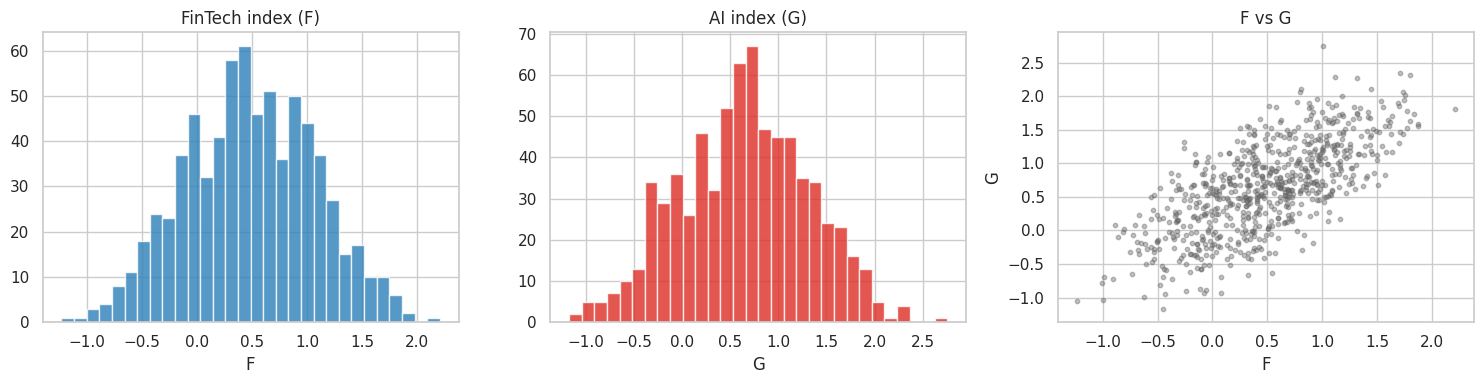

In [5]:
# Distribution of F and G
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(panel["F"].dropna(), bins=30, color="#2c7fb8", alpha=0.8)
axes[0].set_title("FinTech index (F)"); axes[0].set_xlabel("F")
axes[1].hist(panel["G"].dropna(), bins=30, color="#de2d26", alpha=0.8)
axes[1].set_title("AI index (G)"); axes[1].set_xlabel("G")
axes[2].scatter(panel["F"], panel["G"], s=10, alpha=0.4, color="#636363")
axes[2].set_title("F vs G"); axes[2].set_xlabel("F"); axes[2].set_ylabel("G")
plt.tight_layout(); plt.show()

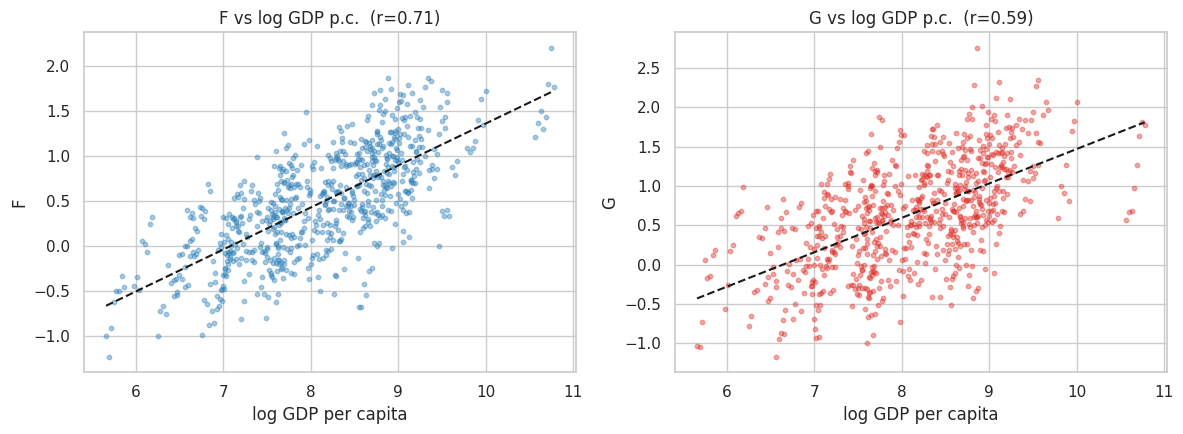

Note: strong F-income and G-income correlations mean residual variation after controlling for income is what identifies the digital effects.


In [6]:
# How do F and G track income? (the identification challenge)
panel["log_gdp"] = np.log(panel["gdp_pc_ppp"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, var, color in zip(axes, ["F", "G"], ["#2c7fb8", "#de2d26"]):
    ax.scatter(panel["log_gdp"], panel[var], s=10, alpha=0.4, color=color)
    # fit line
    m = panel[["log_gdp", var]].dropna()
    b = np.polyfit(m["log_gdp"], m[var], 1)
    xs = np.linspace(m["log_gdp"].min(), m["log_gdp"].max(), 50)
    ax.plot(xs, np.polyval(b, xs), "k--", lw=1.5)
    r = m["log_gdp"].corr(m[var])
    ax.set_title(f"{var} vs log GDP p.c.  (r={r:.2f})")
    ax.set_xlabel("log GDP per capita"); ax.set_ylabel(var)
plt.tight_layout(); plt.show()
print("Note: strong F-income and G-income correlations mean residual variation "
      "after controlling for income is what identifies the digital effects.")

## 2. Index construction check

Confirm the FinTech and AI index builders reproduce the intended methodology.
On the synthetic panel, F and G are supplied directly, so here we instead
verify the construction utilities on the index *components* when running real
data. This cell is illustrative; with real data it calls the actual builders.

In [7]:
from src.utils.data_helpers import zscore, equal_weighted_index, pca_index

# Illustrate equal-weight vs PCA on the available digital sub-measures
# (synthetic panel only has composite F, G; this is a placeholder demonstrating
#  the call pattern used on real component data).
demo = panel[["F", "G"]].dropna().copy()
demo["equal_weight"] = equal_weighted_index(demo, ["F", "G"])
pc, diag = pca_index(demo, ["F", "G"])
demo["pca"] = pc
print("PCA variance explained by first component:", round(diag["variance_explained"], 3))
print("Correlation equal-weight vs PCA:", round(demo["equal_weight"].corr(demo["pca"]), 3))

2026-05-28 12:58:13,736 | src.utils.data_helpers | INFO | pca_index: 1st component explains 84.6% of variance


PCA variance explained by first component: 0.846
Correlation equal-weight vs PCA: 1.0


## 3. Core specifications

We now run the central regressions. We use country and year fixed effects with
country-clustered standard errors throughout, and lag the digital indices one
period to mitigate simultaneity (following Chhetri-Koirala).

In [8]:
from linearmodels.panel import PanelOLS
import statsmodels.api as sm

def prep(df):
    return df.dropna(subset=["iso3", "year"]).set_index(["iso3", "year"]).sort_index()

def lag_within(df, cols, k=1):
    df = df.copy()
    for c in cols:
        if c in df.columns:
            df[f"{c}_L{k}"] = df.groupby(level="iso3")[c].shift(k)
    return df

CONTROLS = ["log_gdp", "trade_pct_gdp", "inflation", "investment_pct_gdp",
            "pop_growth", "credit_to_private_pct_gdp", "secondary_enrollment"]

def run_fe(df, y, X, entity=True, time=True):
    df = prep(df)
    Xc = [c for c in X if c in df.columns]
    d = df[[y] + Xc].dropna()
    mod = PanelOLS(d[y], sm.add_constant(d[Xc]),
                   entity_effects=entity, time_effects=time, drop_absorbed=True)
    return mod.fit(cov_type="clustered", cluster_entity=True)

### Spec 1 — Baseline joint digital  
$g_{it} = \alpha + \beta_1 F + \beta_2 G + \beta_3 (F\times G) + \Gamma X + \mu_i + \lambda_t + \varepsilon$

In [9]:
dfl = lag_within(prep(panel), ["F", "G", "F_x_G"] + CONTROLS).reset_index()
X1 = ["F_L1", "G_L1", "F_x_G_L1"] + [f"{c}_L1" for c in CONTROLS]
spec1 = run_fe(dfl, "gdp_pc_growth", X1)
print(spec1.summary.tables[1])
print(f"\nN = {int(spec1.nobs)},  within-R2 = {spec1.rsquared_within:.4f}")
print(f"Joint-digital coefficient (F x G): {spec1.params.get('F_x_G_L1', float('nan')):.4f}")

                                      Parameter Estimates                                       
                              Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------------------
const                            4.1186     0.5633     7.3114     0.0000      3.0120      5.2253
F_L1                            -1.1243     0.3882    -2.8958     0.0039     -1.8869     -0.3616
G_L1                            -0.4495     0.3417    -1.3152     0.1890     -1.1208      0.2219
F_x_G_L1                         1.1017     0.1650     6.6772     0.0000      0.7776      1.4259
trade_pct_gdp_L1                -0.0047     0.0061    -0.7601     0.4475     -0.0167      0.0074
inflation_L1                    -0.0026     0.0176    -0.1476     0.8827     -0.0373      0.0321
investment_pct_gdp_L1           -0.0071     0.0123    -0.5758     0.5650     -0.0312      0.0170
pop_growth_L1                 

/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


### Spec 4 — MIT interaction (headline)  
Does the joint-digital effect operate specifically in middle-income economies?

In [10]:
dfm = prep(panel).copy()
dfm["F_x_MI"] = dfm["F"] * dfm["mi_status"]
dfm["G_x_MI"] = dfm["G"] * dfm["mi_status"]
dfm["F_x_G_x_MI"] = dfm["F"] * dfm["G"] * dfm["mi_status"]
terms = ["F", "G", "F_x_G", "mi_status", "F_x_MI", "G_x_MI", "F_x_G_x_MI"]
dfm = lag_within(dfm, terms + CONTROLS).reset_index()
X4 = [f"{t}_L1" for t in terms] + [f"{c}_L1" for c in CONTROLS]
spec4 = run_fe(dfm, "gdp_pc_growth", X4)
print(spec4.summary.tables[1])
print(f"\nHEADLINE (F x G x MI): {spec4.params.get('F_x_G_x_MI_L1', float('nan')):.4f}")

                                      Parameter Estimates                                       
                              Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------------------
const                            4.1887     0.5711     7.3341     0.0000      3.0667      5.3107
F_L1                            -2.0302     0.7347    -2.7632     0.0059     -3.4735     -0.5868
G_L1                            -0.3438     0.5509    -0.6242     0.5328     -1.4261      0.7384
F_x_G_L1                         1.0429     0.1916     5.4426     0.0000      0.6664      1.4193
F_x_MI_L1                        1.2163     0.8102     1.5012     0.1339     -0.3754      2.8081
G_x_MI_L1                       -0.0994     0.5733    -0.1735     0.8624     -1.2257      1.0268
F_x_G_x_MI_L1                   -0.0443     0.3125    -0.1417     0.8873     -0.6582      0.5696
trade_pct_gdp_L1              

/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

mi_status_L1, log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


### Spec 3 — Displacement channel  
The labor-displacement term should enter negatively.

In [11]:
terms3 = ["F", "G", "F_x_G", "G_x_H", "G_x_KIS", "displacement_term"]
df3 = lag_within(prep(panel), terms3 + CONTROLS).reset_index()
X3 = [f"{t}_L1" for t in terms3] + [f"{c}_L1" for c in CONTROLS]
spec3 = run_fe(df3, "gdp_pc_growth", X3)
print(spec3.summary.tables[1])
print(f"\nDisplacement coefficient (expect < 0): "
      f"{spec3.params.get('displacement_term_L1', float('nan')):.4f}")

                                      Parameter Estimates                                       
                              Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------------------
const                            4.0435     0.5551     7.2841     0.0000      2.9530      5.1341
F_L1                            -0.8911     0.3943    -2.2601     0.0242     -1.6656     -0.1165
G_L1                            -1.7629     0.8494    -2.0755     0.0384     -3.4316     -0.0943
F_x_G_L1                         0.6678     0.2599     2.5689     0.0105      0.1571      1.1784
G_x_H_L1                         1.8957     1.1731     1.6160     0.1067     -0.4088      4.2002
G_x_KIS_L1                       1.0298     2.1452     0.4801     0.6314     -3.1845      5.2441
displacement_term_L1             7.8336     4.9619     1.5788     0.1150     -1.9141      17.581
trade_pct_gdp_L1              

/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


## 4. Quadrant heterogeneity (Spec 8)

Split countries by median human capital and median KIS share. The joint-digital
effect should be largest in the High-H / High-KIS quadrant and smallest (possibly
negative) in Low-H / Low-KIS.

In [12]:
dq = prep(panel).copy()
h_med = dq["human_capital_pwt"].median()
k_med = dq["sigma_kis"].median()
dq["q_HH"] = ((dq["human_capital_pwt"] >= h_med) & (dq["sigma_kis"] >= k_med)).astype(int)
dq["q_HL"] = ((dq["human_capital_pwt"] >= h_med) & (dq["sigma_kis"] < k_med)).astype(int)
dq["q_LH"] = ((dq["human_capital_pwt"] < h_med) & (dq["sigma_kis"] >= k_med)).astype(int)
dq["q_LL"] = ((dq["human_capital_pwt"] < h_med) & (dq["sigma_kis"] < k_med)).astype(int)
for q in ["HH", "HL", "LH", "LL"]:
    dq[f"FG_{q}"] = dq["F_x_G"] * dq[f"q_{q}"]
termsq = [f"FG_{q}" for q in ["HH", "HL", "LH", "LL"]]
dq = lag_within(dq, termsq + ["F", "G"] + CONTROLS).reset_index()
Xq = ["F_L1", "G_L1"] + [f"{t}_L1" for t in termsq] + [f"{c}_L1" for c in CONTROLS]
spec8 = run_fe(dq, "gdp_pc_growth", Xq)

coefs = {q: spec8.params.get(f"FG_{q}_L1", np.nan) for q in ["HH", "HL", "LH", "LL"]}
ses = {q: spec8.std_errors.get(f"FG_{q}_L1", np.nan) for q in ["HH", "HL", "LH", "LL"]}
print("Joint-digital effect by quadrant:")
for q in ["HH", "HL", "LH", "LL"]:
    print(f"  {q}: {coefs[q]:+.4f}  (se {ses[q]:.4f})")

Joint-digital effect by quadrant:
  HH: +1.1000  (se 0.1837)
  HL: +1.2727  (se 0.2517)
  LH: +1.3017  (se 0.3339)
  LL: +0.9347  (se 0.4141)


/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


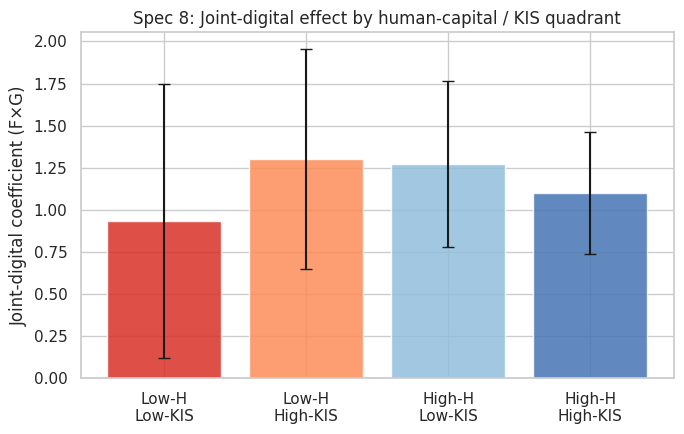

In [13]:
# Visualize the quadrant ordering
fig, ax = plt.subplots(figsize=(7, 4.5))
order = ["LL", "LH", "HL", "HH"]
labels = ["Low-H\nLow-KIS", "Low-H\nHigh-KIS", "High-H\nLow-KIS", "High-H\nHigh-KIS"]
vals = [coefs[q] for q in order]
errs = [1.96 * ses[q] for q in order]
colors = ["#d73027", "#fc8d59", "#91bfdb", "#4575b4"]
ax.bar(labels, vals, yerr=errs, color=colors, alpha=0.85, capsize=4)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Joint-digital coefficient (F×G)")
ax.set_title("Spec 8: Joint-digital effect by human-capital / KIS quadrant")
plt.tight_layout(); plt.show()

## 5. The escape frontier (Spec 9)

Using the Spec 1 coefficients, trace the combinations of FinTech and AI penetration
that deliver growth at the convergence threshold. This is the closed-form result
$F^*(G) = (\bar g - a_G G)/(a_F + a_{FG} G)$.

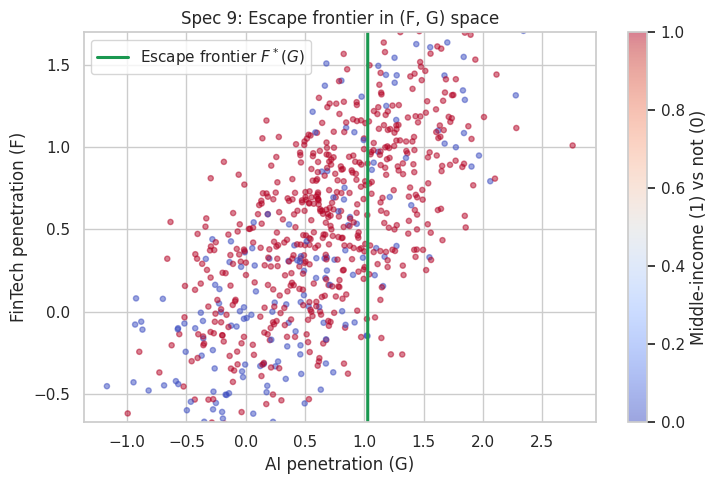

a_F=-1.124, a_G=-0.449, a_FG=1.102, g_bar=2.00
Points above/right of the frontier have enough joint digital adoption to escape.


In [14]:
from config.settings import CONVERGENCE_THRESHOLD_G

a_F = spec1.params.get("F_L1", 0.0)
a_G = spec1.params.get("G_L1", 0.0)
a_FG = spec1.params.get("F_x_G_L1", 0.0)
g_bar = CONVERGENCE_THRESHOLD_G * 100  # percentage points

G_grid = np.linspace(panel["G"].quantile(0.1), panel["G"].quantile(0.9), 200)
denom = a_F + a_FG * G_grid
F_star = np.where(np.abs(denom) > 1e-6, (g_bar - a_G * G_grid) / denom, np.nan)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(G_grid, F_star, color="#1a9850", lw=2.2, label="Escape frontier $F^*(G)$")
sc = ax.scatter(panel["G"], panel["F"], c=panel["mi_status"], cmap="coolwarm",
                s=14, alpha=0.5)
ax.set_xlabel("AI penetration (G)"); ax.set_ylabel("FinTech penetration (F)")
ax.set_title("Spec 9: Escape frontier in (F, G) space")
ax.set_ylim(panel["F"].quantile(0.02), panel["F"].quantile(0.98))
ax.legend()
plt.colorbar(sc, label="Middle-income (1) vs not (0)")
plt.tight_layout(); plt.show()
print(f"a_F={a_F:.3f}, a_G={a_G:.3f}, a_FG={a_FG:.3f}, g_bar={g_bar:.2f}")
print("Points above/right of the frontier have enough joint digital adoption to escape.")

## 6. Threshold regression (Spec 10)

Test for a tipping point in $F\times G$: below the threshold the joint-digital
effect is weak; above it, strong. This is the empirical analogue of the
joint-digital sufficiency condition.

/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)
/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)
/tmp/ipykernel_577/1540695376.py:23: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

log_gdp_L1

  return mod.fit(cov_type="clustered", cluster_entity=True)


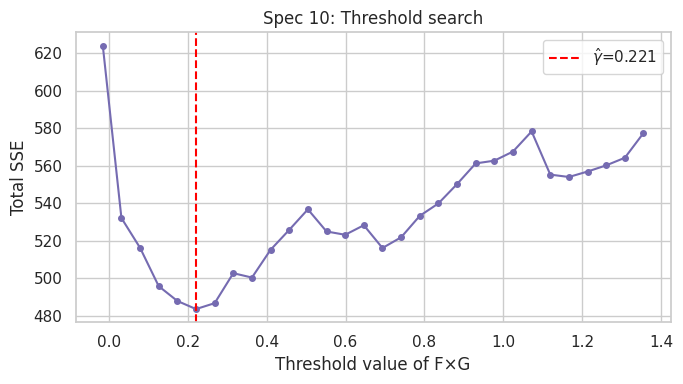

Below threshold: F×G coef = -0.0643
Above threshold: F×G coef = 0.4962


In [15]:
def sse_for_threshold(df, gamma, y="gdp_pc_growth"):
    low = df[df["F_x_G"] < gamma]
    high = df[df["F_x_G"] >= gamma]
    if len(low) < 40 or len(high) < 40:
        return np.nan, None, None
    try:
        rl = run_fe(lag_within(prep(low), ["F","G","F_x_G"]+CONTROLS).reset_index(),
                    y, ["F_L1","G_L1","F_x_G_L1"]+[f"{c}_L1" for c in CONTROLS])
        rh = run_fe(lag_within(prep(high), ["F","G","F_x_G"]+CONTROLS).reset_index(),
                    y, ["F_L1","G_L1","F_x_G_L1"]+[f"{c}_L1" for c in CONTROLS])
        sse = float(rl.resids @ rl.resids) + float(rh.resids @ rh.resids)
        return sse, rl, rh
    except Exception:
        return np.nan, None, None

grid = np.linspace(panel["F_x_G"].quantile(0.15), panel["F_x_G"].quantile(0.85), 30)
sse_path = [sse_for_threshold(panel, g)[0] for g in grid]
best_idx = int(np.nanargmin(sse_path))
gamma_star = grid[best_idx]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, sse_path, "o-", color="#756bb1", ms=4)
ax.axvline(gamma_star, color="red", ls="--", label=f"$\\hat\\gamma$={gamma_star:.3f}")
ax.set_xlabel("Threshold value of F×G"); ax.set_ylabel("Total SSE")
ax.set_title("Spec 10: Threshold search"); ax.legend()
plt.tight_layout(); plt.show()

_, rl, rh = sse_for_threshold(panel, gamma_star)
if rl is not None:
    print(f"Below threshold: F×G coef = {rl.params.get('F_x_G_L1', np.nan):.4f}")
    print(f"Above threshold: F×G coef = {rh.params.get('F_x_G_L1', np.nan):.4f}")

## 7. Trap dynamics: slowdown and exit

Probit models for (a) the probability of a growth slowdown while middle-income
and (b) the hazard of exiting to high-income status.

In [16]:
def run_probit(df, y, X):
    d = df[[y] + X + ["year"]].dropna()
    yd = pd.get_dummies(d["year"], prefix="yr", drop_first=True).astype(float)
    Xd = sm.add_constant(pd.concat([d[X].astype(float), yd], axis=1))
    return sm.Probit(d[y].astype(int), Xd).fit(disp=False)

# Slowdown probit (Spec 5)
df5 = lag_within(prep(panel), ["F","G","F_x_G"]+CONTROLS).reset_index()
X5 = ["F_L1","G_L1","F_x_G_L1"] + [f"{c}_L1" for c in CONTROLS]
slow = df5.dropna(subset=["slowdown_eps"])
spec5 = run_probit(slow, "slowdown_eps", X5)
print("=== Spec 5: Slowdown probit ===")
print(f"F×G coefficient (expect < 0): {spec5.params.get('F_x_G_L1', np.nan):.4f}")
print(f"N = {int(spec5.nobs)}, pseudo-R2 = {spec5.prsquared:.3f}")

=== Spec 5: Slowdown probit ===
F×G coefficient (expect < 0): -1.0057
N = 469, pseudo-R2 = 0.148


In [17]:
# Exit hazard (Spec 6) - among at-risk (middle-income) countries
df6 = panel[panel["at_risk"] == 1].copy()
df6 = lag_within(prep(df6), ["F","G","F_x_G"]+CONTROLS).reset_index()
ex = df6.dropna(subset=["exit"])
if ex["exit"].nunique() > 1:
    spec6 = run_probit(ex, "exit", X5)
    print("=== Spec 6: Exit hazard probit ===")
    print(f"F×G coefficient (expect > 0): {spec6.params.get('F_x_G_L1', np.nan):.4f}")
    print(f"N = {int(spec6.nobs)}, pseudo-R2 = {spec6.prsquared:.3f}")
else:
    print("Exit has no variation in synthetic sample; rerun on real data.")

Exit has no variation in synthetic sample; rerun on real data.


## 8. Results summary

Collect the headline coefficients into one table for quick scanning. On real
data, this becomes the basis for the paper's main results table.

In [18]:
summary_rows = [
    ("Spec 1: Joint digital (F×G)", spec1.params.get("F_x_G_L1", np.nan), spec1.std_errors.get("F_x_G_L1", np.nan)),
    ("Spec 3: Displacement term", spec3.params.get("displacement_term_L1", np.nan), spec3.std_errors.get("displacement_term_L1", np.nan)),
    ("Spec 4: F×G×MI (headline)", spec4.params.get("F_x_G_x_MI_L1", np.nan), spec4.std_errors.get("F_x_G_x_MI_L1", np.nan)),
    ("Spec 8: F×G High-H/High-KIS", coefs["HH"], ses["HH"]),
    ("Spec 8: F×G Low-H/Low-KIS", coefs["LL"], ses["LL"]),
    ("Spec 5: Slowdown F×G", spec5.params.get("F_x_G_L1", np.nan), spec5.bse.get("F_x_G_L1", np.nan)),
]
summary = pd.DataFrame(summary_rows, columns=["Specification", "Coefficient", "Std. Error"])
summary["t-stat"] = summary["Coefficient"] / summary["Std. Error"]
summary

,Specification,Coefficient,Std. Error,t-stat
0,Spec 1: Joint digital (F×G),1.1017,0.1650,6.6772
1,Spec 3: Displacement term,7.8336,4.9619,1.5788
2,Spec 4: F×G×MI (headline),-0.0443,0.3125,-0.1417
3,Spec 8: F×G High-H/High-KIS,1.1000,0.1837,5.9887
4,Spec 8: F×G Low-H/Low-KIS,0.9347,0.4141,2.2572
5,Spec 5: Slowdown F×G,-1.0057,0.3434,-2.9292


### Reading the synthetic results

Because the synthetic DGP embedded a positive $F\times G$ effect, a negative
displacement term, and quadrant ordering (HH > LL), the recovered coefficients
should reflect those signs. **This validates the analysis code, not the hypotheses.**

When you switch to real data (`USE_SYNTHETIC = False`):
1. The signs and magnitudes become substantive findings.
2. Add the IV specifications (Specs 12–14) using `src.analysis.estimators`.
3. Add the McMillan-Rodrik mediator (Spec 11) once `structural_transformation.py` is built.
4. Export tables with `stargazer` for the paper.

### Next steps checklist
- [ ] Download real data (see `README.md` and `config/settings.py` for sources)
- [ ] Run `python -m src.run_pipeline` to build `data/processed/panel.parquet`
- [ ] Replicate Chhetri-Koirala Table 1 to validate the FinTech construction
- [ ] Flip `USE_SYNTHETIC = False` and rerun this notebook
- [ ] Add IV triangulation and export publication tables